In [1]:
import torch
import torchvision

from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

In [3]:
dataset = ImageFolder(
    root="../dataset",
    transform=transform
)

In [4]:
print(dataset)

Dataset ImageFolder
    Number of datapoints: 16500
    Root location: ../dataset
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )


In [5]:
print(dataset.classes)

['Collapsed', 'Damaged', 'Intact']


In [6]:
print(dataset.class_to_idx)

{'Collapsed': 0, 'Damaged': 1, 'Intact': 2}


In [7]:
image, label = dataset[0]

print(image.shape)
print(label)

torch.Size([3, 224, 224])
0


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2042704].


Dataset ImageFolder
    Number of datapoints: 16500
    Root location: ../dataset
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
['Collapsed', 'Damaged', 'Intact']
{'Collapsed': 0, 'Damaged': 1, 'Intact': 2}
torch.Size([224, 224, 3])


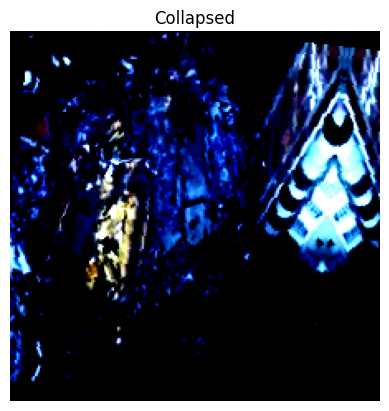

In [9]:
image, label = dataset[0]

image = image.permute(1,2,0)

plt.imshow(image)

plt.title(dataset.classes[label])

plt.axis("off")

print(dataset)
print(dataset.classes)
print(dataset.class_to_idx)
print(image.shape)



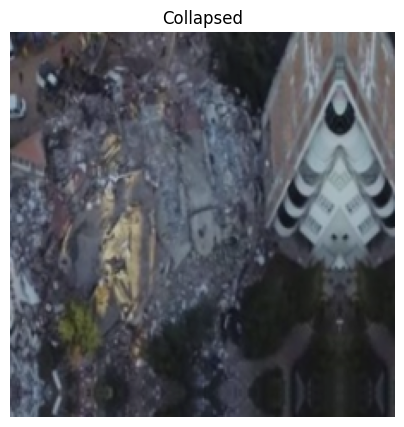

In [10]:
import matplotlib.pyplot as plt

image, label = dataset[0]

# Convert tensor from (C,H,W) → (H,W,C)
image = image.permute(1, 2, 0)

# Convert to numpy
image = image.numpy()

# ImageNet mean and std
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Unnormalize
image = image * std + mean

# Keep values between 0 and 1
image = image.clip(0, 1)

plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title(dataset.classes[label])
plt.axis("off")
plt.show()

In [11]:
from torch.utils.data import random_split

# Total number of images
total_size = len(dataset)

# Split sizes
train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

# Split dataset
train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print(f"Training Images   : {len(train_dataset)}")
print(f"Validation Images : {len(val_dataset)}")
print(f"Testing Images    : {len(test_dataset)}")

Training Images   : 11550
Validation Images : 2475
Testing Images    : 2475


In [12]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 361
Validation batches: 78
Test batches: 78
